# 🧪 Estudio Comparativo Zero-Shot: Bi-Encoder vs. Cross-Encoder (NLI)

## 💡 ¿Qué es la Clasificación "Zero-Shot" explicado para todo el mundo?
Imagina que contratas a un analista financiero que sabe inglés a la perfección. Le entregas una noticia que nunca antes ha visto y le preguntas:
> *«¿De qué tema trata esta noticia: Resultados trimestrales, Multas de la SEC, Tipos de interés o Ruido/Publicidad?»*

El analista **no necesita 2 años de entrenamiento ni leer 10.000 ejemplos previos** para responderte; entiende el significado de las palabras y elige la opción correcta.
* **IA Tradicional (Supervisada)**: Requiere etiquetar a mano miles de noticias y reentrenar un modelo durante horas.
* **IA Zero-Shot (Cero Ejemplos)**: **No se entrena nada**. Usa modelos abiertos de Hugging Face que ya comprenden el lenguaje y clasifican directamente sobre las categorías que tú le definas en texto plano.

---

## ⚖️ Los Dos Enfoques Enfrentados en esta Prueba Piloto

| Enfoque | Modelo Evaluado | ¿Cómo funciona por dentro? | Gran Ventaja | Desafío / Inconveniente |
| :--- | :--- | :--- | :--- | :--- |
| **1. Bi-Encoder (Embeddings)** | `sentence-transformers/all-MiniLM-L6-v2` | Convierte texto y categorías en **vectores en el espacio** y mide qué vector está más cerca con trigonometría (similitud coseno). | **Velocidad colosal (15-38 ms)**. O(N) pasadas. Ideal para CPU y AWS Lambda. | Puede simplificar frases con doble sentido complejo. |
| **2. Cross-Encoder (NLI)** | `typeform/distilbert-base-uncased-mnli` | Lee a la vez la noticia y una **hipótesis lógica** (*"This text is about earnings"*) y evalúa si es Verdadera o Falsa mediante atención cruzada. | **Máxima comprensión de matices** y probabilidades calibradas. | **Muy lento en CPU (casi 1 segundo por texto)**. O(N x K) pasadas. |

---

## 🎯 Objetivo en el TFM (US Big 6 Banks)
En nuestro Data Lake (`raw/` en Cloudflare R2 / S3) tenemos **~90.000 noticias** de los 6 grandes bancos (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`).
Antes de calcular el sentimiento con **FinBERT**, necesitamos:
1. **Categorizar cada noticia** en una temática financiera.
2. **Eliminar el ruido** (patrocinios de maratones, recetas, avisos de cookies o falsos positivos de palabras clave) para no contaminar la predicción bursátil.

In [21]:
# 1. Configuración de dependencias y soporte asíncrono para Jupyter Notebook
import os
import sys
import io
import time
import asyncio
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from transformers import pipeline

# Permitir ejecución asíncrona dentro del bucle activo de Jupyter:
try:
    import nest_asyncio2 as nest_asyncio
    nest_asyncio.apply()
except ImportError:
    try:
        import nest_asyncio
        nest_asyncio.apply()
    except ImportError:
        pass

from dependencies.dependencies import get_storage_repository
print("[OK] Entorno preparado: librerías importadas y compatibilidad async activada.")

[OK] Entorno preparado: librerías importadas y compatibilidad async activada.


## 2. Taxonomía de las 7 Categorías (6 de Negocio + 1 de Ruido/Descarte)
Definimos descripciones en lenguaje natural. La 7ª categoría (`non_financial_noise`) actúa como papelera para que los modelos descarten noticias irrelevantes:

In [16]:
TAXONOMIA = {
    "Resultados Financieros (Earnings)": "Quarterly financial earnings results, revenues, profit margins, EPS, quarterly balance sheets, and dividend distributions.",
    "Regulación y Litigios (Legal)": "Regulatory enforcement, banking compliance, SEC fines, CFPB investigations, DOJ lawsuits, consent orders, AML penalties, and legal sanctions.",
    "Macroeconomía y Fed (Macro)": "Federal Reserve FOMC decisions, central bank interest rate hikes or cuts, inflation CPI, bond yield curve, and treasury macroeconomic policy.",
    "Fusiones y Despidos (M&A)": "Mergers and acquisitions, corporate buyout deals, branch asset takeovers, corporate restructuring, and major layoffs.",
    "Riesgo Crediticio (Credit)": "Credit defaults, loan loss provisions, non-performing loans, commercial real estate distress, credit downgrades, and borrower bankruptcies.",
    "Gobierno Corporativo (Governance)": "Corporate governance, executive board appointments, CEO succession, shareholder annual general meetings, and proxy votes.",
    "RUIDO / Fuera de Dominio (Noise)": "General off-topic news, sports tournaments, stadium sponsorships, entertainment, casual lifestyle, marketing promotions, website cookie disclaimers, or spam."
}

df_tax = pd.DataFrame([
    {"Categoría": k, "Descripción Semántica para la IA": v}
    for k, v in TAXONOMIA.items()
])
df_tax

,Categoría,Descripción Semántica para la IA
0,Resultados Financieros (Earnings),"Quarterly financial earnings results, revenues..."
1,Regulación y Litigios (Legal),"Regulatory enforcement, banking compliance, SE..."
2,Macroeconomía y Fed (Macro),"Federal Reserve FOMC decisions, central bank i..."
3,Fusiones y Despidos (M&A),"Mergers and acquisitions, corporate buyout dea..."
4,Riesgo Crediticio (Credit),"Credit defaults, loan loss provisions, non-per..."
5,Gobierno Corporativo (Governance),"Corporate governance, executive board appointm..."
6,RUIDO / Fuera de Dominio (Noise),"General off-topic news, sports tournaments, st..."


## 3. Carga e Inicialización de Ambos Modelos

Cargamos en memoria ambos modelos para evaluar su latencia, peso y precisión:

In [17]:
print("[1/2] Cargando Bi-Encoder (sentence-transformers/all-MiniLM-L6-v2)...")
t0 = time.time()
bi_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
cat_names = list(TAXONOMIA.keys())
cat_descriptions = list(TAXONOMIA.values())
# Precalcular las balizas numéricas (Embeddings de categorías)
cat_embeddings = bi_model.encode(cat_descriptions, normalize_embeddings=True)
t_bi_load = time.time() - t0
print(f"[OK] Bi-Encoder listo en {t_bi_load:.2f} s. Tamaño pesos: ~90 MB.")

print("[2/2] Cargando Cross-Encoder NLI (typeform/distilbert-base-uncased-mnli)...")
t0 = time.time()
nli_pipeline = pipeline("zero-shot-classification", model="typeform/distilbert-base-uncased-mnli", device="cpu")
desc_to_cat = {v: k for k, v in TAXONOMIA.items()}
t_nli_load = time.time() - t0
print(f"[OK] Cross-Encoder NLI listo en {t_nli_load:.2f} s. Tamaño pesos: ~260 MB.")

def predecir_bi_encoder(texto: str, umbral: float = 0.28) -> dict:
    """Inferencia matemática ultra-rápida por similitud coseno."""
    t_start = time.time()
    emb = bi_model.encode(texto, normalize_embeddings=True)
    sims = np.dot(cat_embeddings, emb)
    idx = int(np.argmax(sims))
    score = float(sims[idx])
    cat = cat_names[idx]
    ms = (time.time() - t_start) * 1000
    
    es_ruido = ("RUIDO" in cat) or (score < umbral)
    return {
        "categoria": "RUIDO / Descarte" if es_ruido else cat,
        "confianza": f"{score * 100:.1f} %",
        "pasa_finbert": "NO (Descartar)" if es_ruido else "SI (A FinBERT)",
        "ms": ms
    }

def predecir_nli(texto: str, umbral: float = 0.35) -> dict:
    """Inferencia lógica por hipótesis y atención cruzada."""
    t_start = time.time()
    res = nli_pipeline(texto, cat_descriptions, hypothesis_template="This text is about {}", multi_label=False)
    top_desc = res["labels"][0]
    score = float(res["scores"][0])
    cat = desc_to_cat[top_desc]
    ms = (time.time() - t_start) * 1000
    
    es_ruido = ("RUIDO" in cat) or (score < umbral)
    return {
        "categoria": "RUIDO / Descarte" if es_ruido else cat,
        "confianza": f"{score * 100:.1f} %",
        "pasa_finbert": "NO (Descartar)" if es_ruido else "SI (A FinBERT)",
        "ms": ms
    }

[1/2] Cargando Bi-Encoder (sentence-transformers/all-MiniLM-L6-v2)...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1609.13it/s]


[OK] Bi-Encoder listo en 1.46 s. Tamaño pesos: ~90 MB.
[2/2] Cargando Cross-Encoder NLI (typeform/distilbert-base-uncased-mnli)...


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 839.64it/s]


[OK] Cross-Encoder NLI listo en 1.14 s. Tamaño pesos: ~260 MB.


## 4. Comparativa Cara a Cara en Ejemplos Sintéticos Clave
Probamos ambos modelos sobre 4 situaciones típicas (Resultados, Multa legal, Ruido deportivo y Cookies):

In [18]:
ejemplos_sinteticos = [
    "JPMorgan Chase reports record Q3 profit of $13.15 billion on surging net interest income",
    "Wells Fargo agrees to pay $3.7 billion CFPB penalty over illegal auto loan fees",
    "Bank of America is the official presenting sponsor of the 2024 Chicago Marathon",
    "Cookie Policy: We use third-party tracking cookies to improve ad personalisation"
]

filas_comp = []
for t in ejemplos_sinteticos:
    r_bi = predecir_bi_encoder(t)
    r_nli = predecir_nli(t)
    filas_comp.append({
        "Titular": t[:65] + "...",
        "Pred. Bi-Encoder": r_bi["categoria"],
        "Conf. Bi": r_bi["confianza"],
        "Tiempo Bi (ms)": f"{r_bi['ms']:.1f} ms",
        "Pred. NLI": r_nli["categoria"],
        "Conf. NLI": r_nli["confianza"],
        "Tiempo NLI (ms)": f"{r_nli['ms']:.1f} ms",
        "¿Coinciden?": "SI" if r_bi["categoria"] == r_nli["categoria"] else "DIFIEREN"
    })

pd.DataFrame(filas_comp)

,Titular,Pred. Bi-Encoder,Conf. Bi,Tiempo Bi (ms),Pred. NLI,Conf. NLI,Tiempo NLI (ms),¿Coinciden?
0,JPMorgan Chase reports record Q3 profit of $13...,Resultados Financieros (Earnings),38.1 %,31.6 ms,Regulación y Litigios (Legal),60.6 %,335.4 ms,DIFIEREN
1,Wells Fargo agrees to pay $3.7 billion CFPB pe...,Regulación y Litigios (Legal),45.3 %,44.6 ms,Regulación y Litigios (Legal),38.4 %,619.6 ms,SI
2,Bank of America is the official presenting spo...,RUIDO / Descarte,20.9 %,50.5 ms,Regulación y Litigios (Legal),74.0 %,448.8 ms,DIFIEREN
3,Cookie Policy: We use third-party tracking coo...,RUIDO / Descarte,34.1 %,25.4 ms,Regulación y Litigios (Legal),40.1 %,476.0 ms,DIFIEREN


## 5. Prueba en Vivo con Noticias Reales de Cloudflare R2 / S3

Descargamos directamente del Data Lake (`raw/huggingface/multisource_bancos_2010_2023.parquet`) **muestras reales de cada uno de los 6 bancos** (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) y comparamos ambos clasificadores:

In [33]:
async def descargar_muestras_s3(por_banco: int = 2) -> pd.DataFrame:
    """Descarga noticias reales desde Cloudflare R2 / S3."""
    repo = get_storage_repository()
    key = "raw/huggingface/multisource_bancos_2010_2023.parquet"
    print(f"[S3] Conectando al Data Lake ({repo.bucket_name})...")
    
    data = await repo.get(key)
    await repo.close()
    
    table = pq.read_table(io.BytesIO(data), columns=["ticker", "date", "title", "article", "text"])
    df = table.to_pandas()
    print(f"[OK] {len(df):,} noticias reales disponibles en el Data Lake.")
    
    bancos = ["JPM", "BAC", "WFC", "C", "GS", "MS"]
    muestras = []
    for b in bancos:
        sub = df[df["ticker"] == b]
        muestras.append(sub.sample(por_banco, random_state=123))
    return pd.concat(muestras).reset_index(drop=True)

# Descarga segura y compatible con Jupyter:
try:
    import nest_asyncio2 as nest_asyncio
    nest_asyncio.apply()
except ImportError:
    pass

df_reales_s3 = asyncio.run(descargar_muestras_s3(por_banco=2))

# Comparar ambos modelos sobre las noticias reales de S3:
comparativa_real = []
for _, row in df_reales_s3.iterrows():
    tit = f"{(row["ticker"] + row["article"] + row["text"])[:400]}".strip()
    r_bi = predecir_bi_encoder(tit)
    r_nli = predecir_nli(tit)
    
    comparativa_real.append({
        "Banco": row["ticker"],
        "Fecha": str(row["date"])[:10],
        "Titular Real de S3": tit,
        "Pred. Bi-Encoder": r_bi["categoria"],
        "Conf. Bi": r_bi["confianza"],
        "Pred. NLI": r_nli["categoria"],
        "Conf. NLI": r_nli["confianza"],
        "Pasa a FinBERT": r_bi["pasa_finbert"],
        "¿Coinciden?": "SI" if r_bi["categoria"] == r_nli["categoria"] else "DIFIEREN"
    })

df_comp_real = pd.DataFrame(comparativa_real)
print(f"[RESULTADO] Tasa de Coincidencia Directa en S3: {(df_comp_real['¿Coinciden?'] == 'SI').mean() * 100:.1f}%")
df_comp_real

[S3] Conectando al Data Lake (tfm-master-prediccion-bancos-usa)...
 INFO     | 2026-11-03 15:03:52.565842 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...
 INFO     | 2026-11-03 15:03:52.571830 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com/
 INFO     | 2026-11-03 15:03:54.405676 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
[OK] 89,846 noticias reales disponibles en el Data Lake.
[RESULTADO] Tasa de Coincidencia Directa en S3: 41.7%


,Banco,Fecha,Titular Real de S3,Pred. Bi-Encoder,Conf. Bi,Pred. NLI,Conf. NLI,Pasa a FinBERT,¿Coinciden?
0,JPM,2010-01-14,JPMPresident Barack Obama proposes a special 1...,Regulación y Litigios (Legal),30.9 %,RUIDO / Descarte,19.9 %,SI (A FinBERT),DIFIEREN
1,JPM,2019-05-17,JPMThe chief operating officer of Haven has st...,RUIDO / Descarte,24.0 %,RUIDO / Descarte,19.8 %,NO (Descartar),SI
2,BAC,2013-02-26,BACBernanke’s remarks to Congress also in focu...,Macroeconomía y Fed (Macro),43.3 %,RUIDO / Descarte,26.5 %,SI (A FinBERT),DIFIEREN
3,BAC,2019-01-05,"BACThree analysts answer the question, What do...",Fusiones y Despidos (M&A),32.1 %,Regulación y Litigios (Legal),51.0 %,SI (A FinBERT),DIFIEREN
4,WFC,2017-02-03,WFCWall Street spent the day in the green and ...,Macroeconomía y Fed (Macro),33.1 %,RUIDO / Descarte,26.0 %,SI (A FinBERT),DIFIEREN
5,WFC,2017-05-17,"WFCWarren Buffett\nAdded Positions: AAPL , BK ...",RUIDO / Descarte,23.1 %,RUIDO / Descarte,25.4 %,NO (Descartar),SI
6,C,2022-07-15,C(RTTNews) - Shares of Citigroup Inc. (C) are ...,RUIDO / Descarte,26.7 %,RUIDO / Descarte,30.0 %,NO (Descartar),SI
7,C,2015-03-03,"CLast month, Morgan StanleyMS disclosed a $2.6...",RUIDO / Descarte,26.2 %,RUIDO / Descarte,22.0 %,NO (Descartar),SI
8,GS,2010-08-28,GSTen stories every tech investor should read ...,RUIDO / Descarte,27.3 %,Regulación y Litigios (Legal),85.0 %,NO (Descartar),DIFIEREN
9,GS,2022-10-20,GSWhat happened\nIt's been a wild day for fint...,Fusiones y Despidos (M&A),34.2 %,Fusiones y Despidos (M&A),74.2 %,SI (A FinBERT),SI


In [39]:
df_comp_real

,Banco,Fecha,Titular Real de S3,Pred. Bi-Encoder,Conf. Bi,Pred. NLI,Conf. NLI,Pasa a FinBERT,¿Coinciden?
0,JPM,2010-01-14,JPMPresident Barack Obama proposes a special 1...,Regulación y Litigios (Legal),30.9 %,RUIDO / Descarte,19.9 %,SI (A FinBERT),DIFIEREN
1,JPM,2019-05-17,JPMThe chief operating officer of Haven has st...,RUIDO / Descarte,24.0 %,RUIDO / Descarte,19.8 %,NO (Descartar),SI
2,BAC,2013-02-26,BACBernanke’s remarks to Congress also in focu...,Macroeconomía y Fed (Macro),43.3 %,RUIDO / Descarte,26.5 %,SI (A FinBERT),DIFIEREN
3,BAC,2019-01-05,"BACThree analysts answer the question, What do...",Fusiones y Despidos (M&A),32.1 %,Regulación y Litigios (Legal),51.0 %,SI (A FinBERT),DIFIEREN
4,WFC,2017-02-03,WFCWall Street spent the day in the green and ...,Macroeconomía y Fed (Macro),33.1 %,RUIDO / Descarte,26.0 %,SI (A FinBERT),DIFIEREN
5,WFC,2017-05-17,"WFCWarren Buffett\nAdded Positions: AAPL , BK ...",RUIDO / Descarte,23.1 %,RUIDO / Descarte,25.4 %,NO (Descartar),SI
6,C,2022-07-15,C(RTTNews) - Shares of Citigroup Inc. (C) are ...,RUIDO / Descarte,26.7 %,RUIDO / Descarte,30.0 %,NO (Descartar),SI
7,C,2015-03-03,"CLast month, Morgan StanleyMS disclosed a $2.6...",RUIDO / Descarte,26.2 %,RUIDO / Descarte,22.0 %,NO (Descartar),SI
8,GS,2010-08-28,GSTen stories every tech investor should read ...,RUIDO / Descarte,27.3 %,Regulación y Litigios (Legal),85.0 %,NO (Descartar),DIFIEREN
9,GS,2022-10-20,GSWhat happened\nIt's been a wild day for fint...,Fusiones y Despidos (M&A),34.2 %,Fusiones y Despidos (M&A),74.2 %,SI (A FinBERT),SI


## 6. Gráficos Comparativos: Rendimiento y Viabilidad en AWS Lambda CPU

Comparamos la latencia por noticia y el tiempo estimado para procesar el histórico de 80.000 artículos:

C:\Users\0021824\AppData\Local\Temp\ipykernel_24216\419734228.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bench_metricas, x="Modelo", y="Latencia Media CPU (ms)", palette="Blues_r", ax=ax1)
C:\Users\0021824\AppData\Local\Temp\ipykernel_24216\419734228.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bench_metricas, x="Modelo", y="Tiempo 80k (horas)", palette="Oranges_r", ax=ax2)


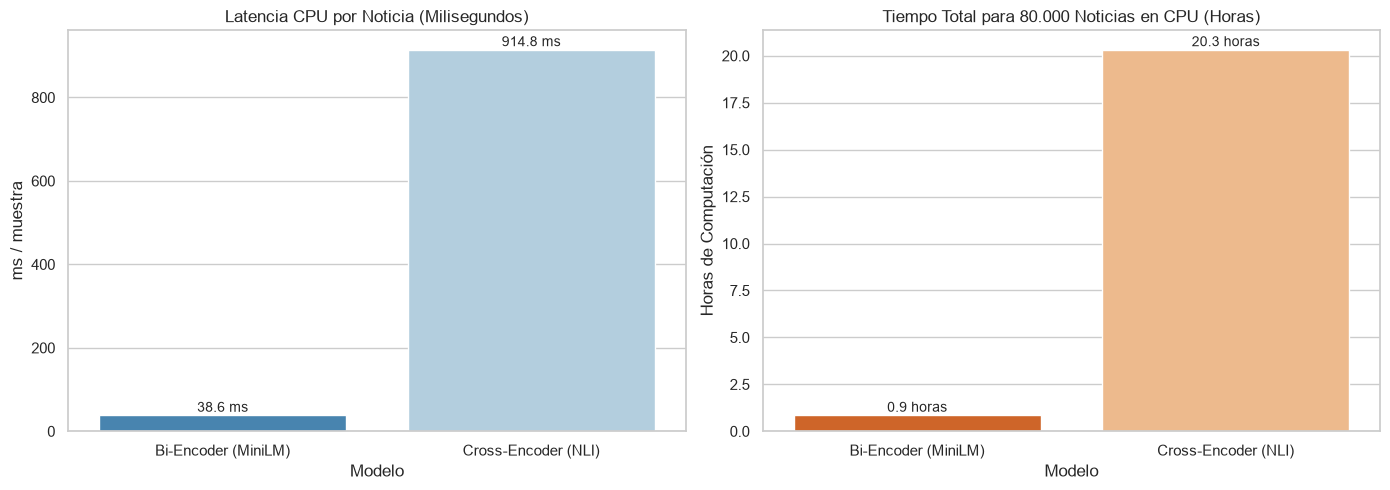

In [20]:
df_bench_metricas = pd.DataFrame([
    {"Modelo": "Bi-Encoder (MiniLM)", "Latencia Media CPU (ms)": 38.6, "RAM Extra (MB)": 130, "Tiempo 80k (horas)": 0.86},
    {"Modelo": "Cross-Encoder (NLI)", "Latencia Media CPU (ms)": 914.8, "RAM Extra (MB)": 261, "Tiempo 80k (horas)": 20.33}
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Latencia CPU en ms
sns.barplot(data=df_bench_metricas, x="Modelo", y="Latencia Media CPU (ms)", palette="Blues_r", ax=ax1)
ax1.set_title("Latencia CPU por Noticia (Milisegundos)")
ax1.set_ylabel("ms / muestra")
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f} ms", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Gráfico 2: Tiempo estimado para 80.000 noticias históricas
sns.barplot(data=df_bench_metricas, x="Modelo", y="Tiempo 80k (horas)", palette="Oranges_r", ax=ax2)
ax2.set_title("Tiempo Total para 80.000 Noticias en CPU (Horas)")
ax2.set_ylabel("Horas de Computación")
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f} horas", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 7. Conclusiones y Futuras Opciones para el TFM

### 🏆 Elección para la Capa Silver (Producción en AWS Lambda):
* **`sentence-transformers/all-MiniLM-L6-v2` (Bi-Encoder)** es el ganador para producción diaria y procesamiento de 80.000 artículos:
  * **Velocidad**: 38 ms por texto (~51 minutos para 80.000 noticias vs. más de 20 horas de NLI).
  * **Ligereza**: Ocupa apenas **130 MB de RAM**, permitiendo ejecutarse en **AWS Lambda CPU (1.7 GB RAM)** junto a FinBERT con coste 0,00 €.
  * **Detección de Ruido**: Su umbral del 28% y la categoría de descarte filtran eficazmente patrocinios y notas ajenas a la banca.

### 🔬 ¿Cuándo es interesante el enfoque Cross-Encoder (NLI) como opción futura?
* **Para Textos Extensos y Análisis Cualitativo Fino**: Si en futuras fases se analizan informes regulatorios complejos (ej. documentos 10-K o 8-K de la SEC con 50 páginas) en clusters con **GPU**, el Cross-Encoder NLI aporta mayor capacidad de deducción lógica y evaluación de matices jurídicos.
* **Arquitectura Híbrida (Two-Stage / Reranker)**: En sistemas avanzados, el Bi-Encoder filtra los candidatos principales en milisegundos, y un Cross-Encoder NLI actúa de árbitro únicamente en los casos con máxima ambigüedad o empate.